# Basic Tutorial: Your First Energy System Model

This tutorial walks you through a complete energy system model with **ETHOS.FINE**, from an empty model to interpreted results. No prior knowledge of FINE is needed, only some basic Python and pandas.

We model the electricity supply of **Germany**, divided into **two regions**, `north` and `south`, over **three investment periods** (2020, 2030 and 2040). The system has to cover a growing electricity demand while the allowed CO<sub>2</sub> emissions shrink from period to period. FINE then decides, at minimal total cost, **what to build where and when**, and **how to operate it hour by hour**.

The model contains one example of each of the five basic component types of FINE:

| Component type | In this tutorial | What it does |
|---|---|---|
| **Source** | Wind turbines, PV, natural gas import | brings a commodity into the system |
| **Sink** | Electricity demand, CO<sub>2</sub> to environment | takes a commodity out of the system |
| **Conversion** | Gas power plants | turns commodities into other commodities |
| **Storage** | Batteries | shifts a commodity in time |
| **Transmission** | AC cables | moves a commodity between regions |

To keep it simple, the model starts from an empty system (no existing power plants or grid) and contains only these few technologies. Every step below explains only the parameters that are used. The notebooks of the *Modular Examples* go through each component type in depth and list all of its parameters.

After importing the packages, the workflow is always the same, and each step has its own section below:

- Prepare the input data
- Create the `EnergySystemModel`
- Add components
- Optimize
- Look at the results

## 1. Import packages

`fine` is usually imported as `fn`. `pandas` reads the input data, and `matplotlib` arranges some of the plots.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

## 2. Prepare the input data

FINE works with plain pandas objects, so input data can come from anywhere: CSV or Excel files, databases, other models. In this tutorial we read CSV files that come with FINE in the folder `examples/data/twoRegions`. They were derived from FINE's larger example data set, which divides Germany into eight regions, by merging these into two regions (the script `createTwoRegionData.py` in the same folder shows how).

The two regions:

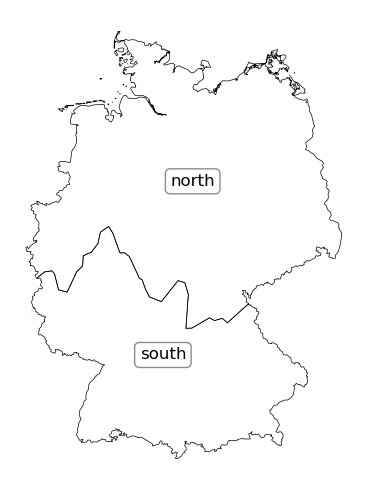

In [2]:
dataPath = Path("../../data/twoRegions")  # relative to the folder of this notebook

fn.plotLocations(
    dataPath / "regions.geojson",
    indexColumn="region",
    plotLocNames=True,
    figsize=(4, 5),
);

**Time series** are `pd.DataFrame`s with one row per time step (here: the 8760 hours of a year) and one column per region. We need three of them:

- **Wind capacity factors**: how much one unit of installed wind turbine capacity can produce in each hour (between 0 and 1). A value of 0.3 means that 1 GW of wind turbines can produce at most 0.3 GW in that hour.
- **PV capacity factors**, defined the same way.
- **Electricity demand** in GW.

In [3]:
windCapacityFactor = pd.read_csv(dataPath / "windCapacityFactor.csv", index_col=0)
pvCapacityFactor = pd.read_csv(dataPath / "pvCapacityFactor.csv", index_col=0)
electricityDemand2020 = pd.read_csv(dataPath / "electricityDemand.csv", index_col=0)

electricityDemand2020.head()

,north,south
hour,,
0,27.454,18.596
1,26.190,17.707
2,25.973,16.563
3,25.259,15.857
4,24.586,15.182


On average over the year, wind turbines in the north produce about 50 % more per installed GW than in the south, while PV produces about the same in both regions:

In [4]:
meanCapacityFactor = {"Wind": windCapacityFactor.mean(), "PV": pvCapacityFactor.mean()}
pd.DataFrame(meanCapacityFactor).round(3)

,Wind,PV
north,0.257,0.121
south,0.179,0.128


The capacity factors change a lot over the year. Here are two weeks, one in winter and one in summer. From 21 to 27 January, PV produces only a little around noon, and the wind changes a lot from day to day. When it blows, it blows much more strongly in the north than in the south. From 1 to 7 July, PV produces a lot around noon every day, and the wind is mostly weak in both regions.

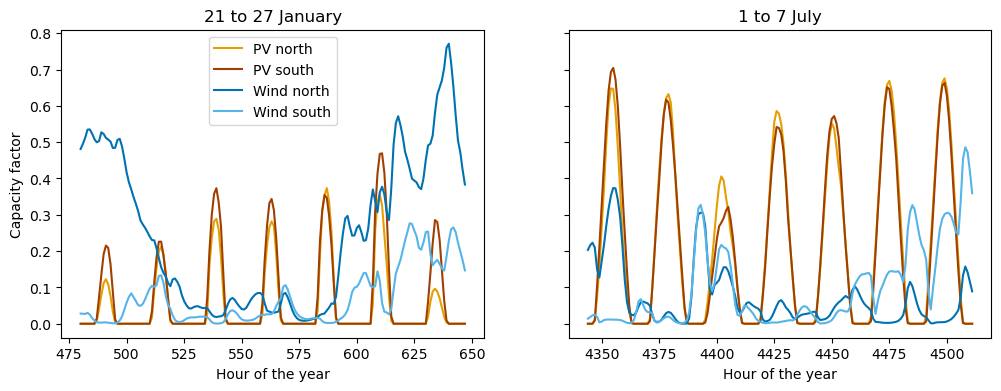

In [5]:
# Hours of the year in each week
weeks = {"21 to 27 January": range(480, 648), "1 to 7 July": range(4344, 4512)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, hours) in zip(axes, weeks.items()):
    pv = pvCapacityFactor.loc[hours].add_prefix("PV ")
    wind = windCapacityFactor.loc[hours].add_prefix("Wind ")
    pv.plot(ax=ax, color=["#E69F00", "#A04000"], legend=False)
    wind.plot(ax=ax, color=["#0072B2", "#56B4E9"], legend=False)
    ax.set(title=title, xlabel="Hour of the year", ylabel="Capacity factor")
axes[0].legend(loc="upper center");

How much capacity may be built at all (the *potential*) depends, for example, on the land available for wind turbines and PV. The potentials in GW per technology and region are set later with the parameter `capacityMax` when adding the components. Finally, the distance between the centers of the two regions in km is needed for the AC cables between them.

In [6]:
capacityPotential = pd.read_csv(dataPath / "capacityPotential.csv", index_col=0)
distances = pd.read_csv(dataPath / "distances.csv", index_col=0)

capacityPotential.loc[["Wind (onshore)", "PV"]]

,north,south
technology,,
Wind (onshore),267.9,145.3
PV,111.7,78.0


## 3. Create the energy system model

The `EnergySystemModel` (usually called `esM`) is the container for everything else. It defines the *frame* of the model, which all components added later have to fit into:

- **`locations`**: the regions (nodes) of the model. Every component exists in some or all of them.
- **`commodities`** and **`commodityUnitsDict`**: the energy carriers or materials that flow through the system and the unit in which each of them is measured. FINE does not convert units for you; it is your job to give all inputs of a commodity consistently in this unit. Here, electricity and natural gas are measured in GW and CO<sub>2</sub> in million tonnes per hour.
- **`numberOfTimeSteps`** and **`hoursPerTimeStep`**: the temporal resolution of the operation. We model every hour of a year.
- **`numberOfInvestmentPeriods`**, **`investmentPeriodInterval`** and **`startYear`**: the *investment periods* in which FINE may build new capacity. With three periods, an interval of 10 years and a start year of 2020, these are 2020, 2030 and 2040. Each of them is represented by one full year of operation, and capacity built in one period remains available in later periods until it reaches the end of its lifetime.
- **`costUnit`** and **`lengthUnit`**: the units of all cost and length (distance) inputs.

### A CO<sub>2</sub> limit per investment period

To make the investment periods differ, we cap the CO<sub>2</sub> emissions of the whole system: 90 million tonnes in 2020, 45 in 2030 and 20 in 2040. For comparison: covering the whole electricity demand of 2020 with gas power plants alone would emit about 177 million tonnes. Limits like this are defined with **`balanceLimit`**: each row is a limit with an ID (here `"CO2 limit"`), the column `"Total"` holds the value for the whole system (a column per region would hold regional limits instead), and components later join the limit by referring to its ID.

Two conventions are important here:

- Commodity flows that **leave** the system (into a `Sink`) count as **negative** in a balance limit.
- `lowerBound=True` means the balance must be **greater than or equal** to the value.

So a value of `-90` with `lowerBound=True` reads as *"at most 90 million tonnes of CO<sub>2</sub> may leave the system"*. Many FINE parameters accept a dictionary with the investment periods (as calendar years) as keys if their value should differ between periods, and `balanceLimit` is one of them.

In [7]:
regions = ["north", "south"]
investmentPeriods = [2020, 2030, 2040]
co2LimitPerPeriod = {2020: 90, 2030: 45, 2040: 20}  # million tonnes of CO2 per year

balanceLimit = {
    year: pd.DataFrame(
        index=["CO2 limit"],
        columns=["Total", "lowerBound"],
        data=[[-limit, True]],
    )
    for year, limit in co2LimitPerPeriod.items()
}

esM = fn.EnergySystemModel(
    locations=set(regions),
    commodities={"electricity", "naturalGas", "CO2"},
    commodityUnitsDict={
        "electricity": "GW_el",
        "naturalGas": "GW_CH4",
        "CO2": "Mt_CO2/h",
    },
    numberOfTimeSteps=8760,
    hoursPerTimeStep=1,
    numberOfInvestmentPeriods=3,
    investmentPeriodInterval=10,
    startYear=2020,
    costUnit="1e6 Euro",
    lengthUnit="km",
    balanceLimit=balanceLimit,
    verboseLogLevel=1,  # only print warnings
)

## 4. Add components

The model is still empty. In the following subsections we add components with `esM.add(...)`, one subsection per component type. Every component needs at least a reference to the model (`esM=esM`), a unique `name` and the commodity or commodities it handles. All other parameters have sensible defaults.

Most components below use the same handful of parameters, so here they are once:

- **`hasCapacityVariable`**: if `True`, FINE optimizes the *size* (capacity) of the component in every region and investment period. If `False`, the component has no capacity, only an operation (useful for fuel imports or fixed demands).
- **`capacityMax`**: an upper limit for the capacity, e.g. the potential of wind turbines. It can be given as a single number (the same for all regions and investment periods), as a `pd.Series` with one value per region (the same for all investment periods), or as a dictionary with the investment periods as keys and one of the two as values.
- **`investPerCapacity`** and **`opexPerCapacity`**: investment cost and yearly fixed operation cost per unit of capacity, in `costUnit` per capacity unit (here: million Euro per GW).
- **`interestRate`** and **`economicLifetime`**: used to spread the investment into yearly payments (annuities).
- **`technicalLifetime`**: how long the capacity physically exists before it is decommissioned. Defaults to the economic lifetime.

Cost parameters can be given as a dictionary keyed by investment period. We use this to let renewables and batteries become cheaper over time.

### Sources

A **`Source`** brings a commodity into the system. Its operation in every hour is a decision of the optimization, limited by its capacity.

**Wind turbines and PV** have a capacity variable. The parameter **`operationRateMax`** limits their hourly production to *capacity factor × installed capacity*, which is exactly what the capacity-factor time series describe. Whenever the wind does not blow, the turbines cannot produce, however many are built. Their potential, one row of `capacityPotential`, is a `pd.Series` per region and goes into `capacityMax`.

The [Sources notebook](_3_sources.ipynb) adds offshore wind turbines, which can only be built in the north, a political expansion target and existing run-of-river plants.

In [8]:
esM.add(
    fn.Source(
        esM=esM,
        name="Wind turbines",
        commodity="electricity",
        hasCapacityVariable=True,
        operationRateMax=windCapacityFactor,
        capacityMax=capacityPotential.loc["Wind (onshore)"],  # GW
        investPerCapacity={2020: 1300, 2030: 1150, 2040: 1050},  # million Euro per GW
        opexPerCapacity=30,  # million Euro per GW and year
        interestRate=0.08,
        economicLifetime=20,
    )
)

esM.add(
    fn.Source(
        esM=esM,
        name="PV",
        commodity="electricity",
        hasCapacityVariable=True,
        operationRateMax=pvCapacityFactor,
        capacityMax=capacityPotential.loc["PV"],
        investPerCapacity={2020: 750, 2030: 500, 2040: 380},
        opexPerCapacity=12,
        interestRate=0.08,
        economicLifetime=25,
    )
)

**Natural gas** is simply bought at a price. It has no capacity variable, so FINE can import any amount in any hour, and every unit costs **`commodityCost`** (here: million Euro per GWh, i.e. 25 to 35 Euro per MWh, rising over time).

In [9]:
esM.add(
    fn.Source(
        esM=esM,
        name="Natural gas import",
        commodity="naturalGas",
        hasCapacityVariable=False,
        commodityCost={2020: 0.025, 2030: 0.03, 2040: 0.035},
    )
)

### Conversions

A **`Conversion`** turns one or more commodities into one or more others. Its capacity is measured in the **`physicalUnit`**, and **`commodityConversionFactors`** state how much of every commodity is produced (positive) or consumed (negative) per unit of operation.

Our gas power plants have an efficiency of 60 %. Producing 1 GWh of electricity therefore consumes 1/0.6 GWh of natural gas and, at 201 t CO<sub>2</sub> per GWh of gas, emits 201/0.6 t (= 201×10<sup>-6</sup>/0.6 million tonnes) of CO<sub>2</sub>.

The [Conversions notebook](_5_conversions.ipynb) adds gas power plants that already exist at the start and electrolyzers that produce hydrogen.

In [10]:
esM.add(
    fn.Conversion(
        esM=esM,
        name="Gas power plants",
        physicalUnit="GW_el",
        commodityConversionFactors={
            "electricity": 1,
            "naturalGas": -1 / 0.6,
            "CO2": 201e-6 / 0.6,
        },
        hasCapacityVariable=True,
        investPerCapacity=650,
        opexPerCapacity=20,
        interestRate=0.08,
        economicLifetime=30,
    )
)

### Storages

A **`Storage`** shifts a commodity from one hour to a later one. Its capacity is the amount it can hold (here GWh). The most important technical parameters are

- **`chargeEfficiency`** and **`dischargeEfficiency`**: losses when charging and discharging,
- **`selfDischarge`**: the share of the content lost per hour. We assume 3 % per month, which corresponds to 1 − 0.97<sup>1/720</sup> ≈ 0.0042 % (4.23×10<sup>-5</sup>) per hour,
- **`chargeRate`** and **`dischargeRate`**: how much of the capacity can be charged or discharged within one hour. A rate of 1 means the battery can be fully charged or emptied in one hour,
- **`opexPerChargeOperation`**: a cost per unit of charged electricity, e.g. for wear (here 1 Euro per MWh).

The [Storages notebook](_6_storages.ipynb) adds existing pumped hydro storage and hydrogen storage in salt caverns, which can shift energy from one season to another.

In [11]:
esM.add(
    fn.Storage(
        esM=esM,
        name="Batteries",
        commodity="electricity",
        hasCapacityVariable=True,
        chargeEfficiency=0.95,
        dischargeEfficiency=0.95,
        selfDischarge=4.23e-5,  # per hour
        chargeRate=1,
        dischargeRate=1,
        opexPerChargeOperation=0.001,  # million Euro per GWh
        investPerCapacity={2020: 300, 2030: 180, 2040: 120},  # million Euro per GWh
        opexPerCapacity=3,
        interestRate=0.08,
        economicLifetime=10,
    )
)

### Transmissions

A **`Transmission`** moves a commodity between regions. Its inputs refer to *pairs* of regions, so they are given as square `pd.DataFrame`s with regions as both index and columns, like the `distances` we read in section 2.

- **`distances`**: the length of each connection in `lengthUnit`.
- **`losses`**: the share of the transported electricity lost per km (0.01 % per km, i.e. about 3.6 % over the 357 km between the two regions).
- **`investPerCapacity`** and **`opexPerCapacity`** are given *per capacity and per km*, so longer connections are more expensive.

A capacity is optimized for each connection, so that the north and the south can exchange wind and solar power.

The [Transmissions notebook](_7_transmissions.ipynb) adds the existing grid and HVDC cables.

In [12]:
esM.add(
    fn.Transmission(
        esM=esM,
        name="AC cables",
        commodity="electricity",
        hasCapacityVariable=True,
        distances=distances,
        losses=0.0001,
        investPerCapacity=1.5,  # million Euro per GW and km
        opexPerCapacity=0.015,
        interestRate=0.08,
        economicLifetime=40,
    )
)

### Sinks

A **`Sink`** takes a commodity out of the system.

The **electricity demand** must be met exactly in every hour, so it is given as **`operationRateFix`**: a fixed hourly operation instead of an upper limit. The demand grows by 15 % per decade. Time series can, just like costs, be given as a dictionary with one `DataFrame` per investment period.

In [13]:
electricityDemand = {
    2020: electricityDemand2020,
    2030: electricityDemand2020 * 1.15,
    2040: electricityDemand2020 * 1.15**2,
}

esM.add(
    fn.Sink(
        esM=esM,
        name="Electricity demand",
        commodity="electricity",
        hasCapacityVariable=False,
        operationRateFix=electricityDemand,
    )
)

The **CO<sub>2</sub> emitted by the gas power plants** also has to go somewhere, otherwise the CO<sub>2</sub> balance of each region could not be closed and the plants could not run at all. This sink has no limit of its own, but with **`balanceLimitID="CO2 limit"`** it joins the CO<sub>2</sub> limit defined in section 3, so its total yearly operation (the emissions) is capped per investment period.

The [Sinks notebook](_4_sinks.ipynb) replaces the CO<sub>2</sub> limit by a CO<sub>2</sub> price and adds electricity exports.

In [14]:
esM.add(
    fn.Sink(
        esM=esM,
        name="CO2 to environment",
        commodity="CO2",
        hasCapacityVariable=False,
        balanceLimitID="CO2 limit",
    )
)

## 5. Optimize

The model is complete. Before solving it, we reduce its size with **time series aggregation**: instead of all 365 days of a year, the model only operates **8 typical days**, which are clustered from the original time series and weighted by how often they occur. FINE uses the package [tsam](https://github.com/FZJ-IEK3-VSA/tsam) (time series aggregation module) for this. This makes the optimization much faster at the cost of some accuracy (e.g. long calm periods are smoothed out). For real studies you would check how many typical days are needed; for learning, 8 are enough.

Then `esM.optimize` builds the optimization problem and hands it to a solver. FINE minimizes the total discounted cost of investment and operation across all investment periods. `STANDARD_SOLVER` uses the commercial solver Gurobi if a full license is available and the free open-source solver [HiGHS](https://highs.dev/) otherwise. Both are installed together with FINE; you can also choose one directly, e.g. `solver="highs"`. When you run the notebook, the solver prints a log while it works; its last lines report that an optimal solution was found. (The log is not shown on the documentation website.)

In [15]:
esM.aggregateTemporally(numberOfTypicalPeriods=8)

In [16]:
esM.optimize(
    timeSeriesAggregation=True,
    solver=fn.utils.ImplementedSolvers.STANDARD_SOLVER.value,
)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (72 outputs left out)

Solved with barrier


    2284    5.9589260e+05   0.000000e+00   0.000000e+00      1s


Solved in 2284 iterations and 0.64 seconds (0.67 work units)


Optimal objective  5.958925952e+05


## 6. Look at the results

### Optimization summaries

The main entry point to the results is **`esM.getOptimizationSummary`**. It returns a table per *modeling class* (all sources and sinks together, all conversions, all storages, all transmissions) and per investment period. The rows are component, property and unit; the columns are the regions. `outputLevel=2` hides components that were not used.

Here are the sources and sinks in 2040:

In [17]:
esM.getOptimizationSummary("SourceSinkModel", outputLevel=2, ip=2040)

north  \
Component          Property                        Unit                            
CO2 to environment operation                       [Mt_CO2/h*h]         9.210437   
                   operation_annual                [Mt_CO2/h*h/a]       9.210437   
Electricity demand operation                       [GW_el*h]       397882.241183   
                   operation_annual                [GW_el*h/a]     397882.241183   
Natural gas import NPVcontribution                 [1e6 Euro]        2493.610754   
                   TAC                             [1e6 Euro/a]      1603.807455   
                   commodCosts                     [1e6 Euro/a]      1603.807455   
                   operation                       [GW_CH4*h]       45823.070141   
                   operation_annual                [GW_CH4*h/a]     45823.070141   
PV                 NPVcontribution                 [1e6 Euro]       10056.423803   
                   TAC                             [1e6 Euro/a]      6467.957134   
                   capacity                        [GW_el]                 111.7   
                   capexCap                        [1e6 Euro/a]      5127.557134   
                   commissioning                   [GW_el]              9.287293   
                   decommissioning                 [GW_el]              9.287293   
                   invest                          [1e6 Euro]        3529.171455   
                   operation                       [GW_el*h]       115540.964125   
                   operation_annual                [GW_el*h/a]     115540.964125   
                   opexCap                         [1e6 Euro/a]           1340.4   
                   revenueLifetimeShorteningResale [1e6 Euro]         705.834291   
Wind turbines      NPVcontribution                 [1e6 Euro]        58341.32679   
                   TAC                             [1e6 Euro/a]     37523.199921   
                   capacity                        [GW_el]                 267.9   
                   capexCap                        [1e6 Euro/a]     29486.199921   
                   commissioning                   [GW_el]            185.851427   
                   decommissioning                 [GW_el]             80.393899   
                   invest                          [1e6 Euro]      195143.998267   
                   operation                       [GW_el*h]       324014.692142   
                   operation_annual                [GW_el*h/a]     324014.692142   
                   opexCap                         [1e6 Euro/a]           8037.0   

                                                                           south  
Component          Property                        Unit                           
CO2 to environment operation                       [Mt_CO2/h*h]        10.789563  
                   operation_annual                [Mt_CO2/h*h/a]      10.789563  
Electricity demand operation                       [GW_el*h]       300265.533945  
                   operation_annual                [GW_el*h/a]     300265.533945  
Natural gas import NPVcontribution                 [1e6 Euro]        2921.139333  
                   TAC                             [1e6 Euro/a]       1878.77961  
                   commodCosts                     [1e6 Euro/a]       1878.77961  
                   operation                       [GW_CH4*h]       53679.417421  
                   operation_annual                [GW_CH4*h/a]     53679.417421  
PV                 NPVcontribution                 [1e6 Euro]        5772.530779  
                   TAC                             [1e6 Euro/a]        3712.6997  
                   capacity                        [GW_el]                  78.0  
                   capexCap                        [1e6 Euro/a]        2776.6997  
                   commissioning                   [GW_el]             77.994601  
                   decommissioning                 [GW_el]

The most important properties are

- `capacity`: the installed capacity in that period (everything still in operation, not only what was newly built),
- `commissioning`: the capacity newly built in that period,
- `operation`: the yearly sum of the hourly operation, e.g. the yearly electricity production in GWh,
- `TAC`: the total annual cost of the component in that period (`capexCap`, `opexCap`, `opexOp`, `commodCosts`, ... break it down).

### How the system develops over time

To compare the investment periods, we collect the **capacity** and the yearly electricity **generation** (the property `operation`) of the power generators per region from the summaries of every period and plot them as stacked bar charts, in the colors of the capacity factors above. The capacity is cumulative: it contains everything built so far that has not yet reached the end of its lifetime. (The batteries are left out: they only shift electricity in time, and their capacity is measured in GWh instead of GW.)

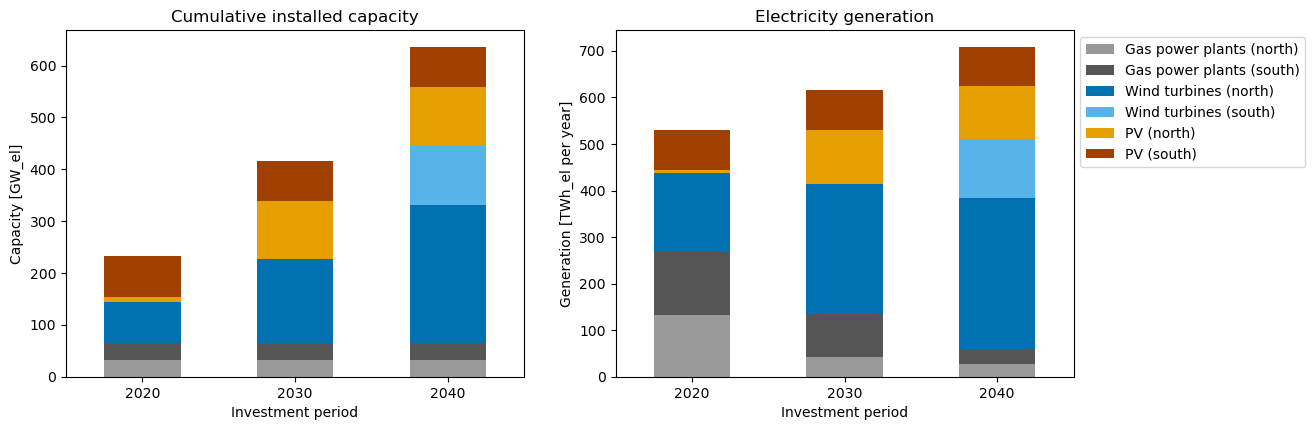

In [18]:
# Colors per generator and region, as in the plot of the capacity factors
colors = {
    ("Gas power plants", "north"): "#999999",
    ("Gas power plants", "south"): "#555555",
    ("Wind turbines", "north"): "#0072B2",
    ("Wind turbines", "south"): "#56B4E9",
    ("PV", "north"): "#E69F00",
    ("PV", "south"): "#A04000",
}
columns = [f"{component} ({region})" for component, region in colors]
capacity = pd.DataFrame(0.0, index=investmentPeriods, columns=columns)
generation = capacity.copy()

for year in investmentPeriods:
    for modelingClass in ["SourceSinkModel", "ConversionModel"]:
        summary = esM.getOptimizationSummary(modelingClass, outputLevel=1, ip=year)
        capacities = summary.xs("capacity", level="Property").droplevel("Unit")
        operations = summary.xs("operation", level="Property").droplevel("Unit")
        for component, region in colors:
            if component in capacities.index:
                column = f"{component} ({region})"
                capacity.loc[year, column] = capacities.loc[component, region]
                generation.loc[year, column] = (
                    operations.loc[component, region] / 1000
                )  # TWh

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotSettings = dict(
    stacked=True, color=list(colors.values()), rot=0, xlabel="Investment period"
)
capacity.plot.bar(
    ax=axes[0],
    legend=False,
    ylabel="Capacity [GW_el]",
    title="Cumulative installed capacity",
    **plotSettings,
)
generation.plot.bar(
    ax=axes[1],
    ylabel="Generation [TWh_el per year]",
    title="Electricity generation",
    **plotSettings,
)
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1));

The CO<sub>2</sub> limit drives the transformation:

- **2020:** gas power plants still produce about half of the electricity. The other half comes mainly from wind turbines in the windy north and PV in the south. AC cables are built right away; they mostly carry northern wind power to the south.
- **2030:** the CO<sub>2</sub> limit is halved and renewables become cheaper. The PV potential of both regions is used completely, the wind turbines in the north double, and batteries store the PV surplus of the middle of the day for the evening.
- **2040:** with only 20 million tonnes of CO<sub>2</sub> left, the whole wind potential of the north is used, and wind turbines are now also built in the less windy south. The northern wind turbines built in 2020 reach the end of their 20-year lifetime and are replaced (see `commissioning` and `decommissioning` in the summary table above).

The two charts tell different stories about the gas power plants: their **capacity** stays the same, because plants built in 2020 have a lifetime of 30 years and still exist in 2040. Their **generation**, however, drops from about 270 TWh in 2020 to about 60 TWh in 2040. In the end they mainly serve as backup for hours with little wind and sun (see their operation below).

### Looking at the operation

FINE also provides plotting functions for single components. `fn.plotOperationColorMap` shows the hourly operation of a component in one region as a heat map, with the days of the year on the x-axis and the hours of the day on the y-axis. Since we optimized with 8 typical days, each year is assembled from those 8 days.

Here is when the batteries in the south are charged in 2030: around the middle of the day, with surplus PV power. They are discharged in the evening, which you can see by plotting `dischargeOperationVariablesOptimum` instead.

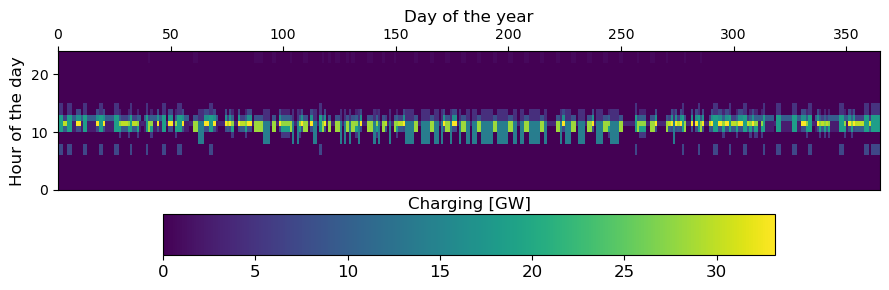

In [19]:
fn.plotOperationColorMap(
    esM,
    "Batteries",
    "south",
    variableName="chargeOperationVariablesOptimum",  # plot the charging (not the discharging)
    ip=2030,
    figsize=(9, 3),
    xlabel="Day of the year",
    ylabel="Hour of the day",
    zlabel="Charging [GW]",
);

And the electricity production of the gas power plants in the south in 2040, where they are mainly a backup: in winter, they run on days with little wind, often from the early morning to the late evening. In summer, they only run on some evenings.

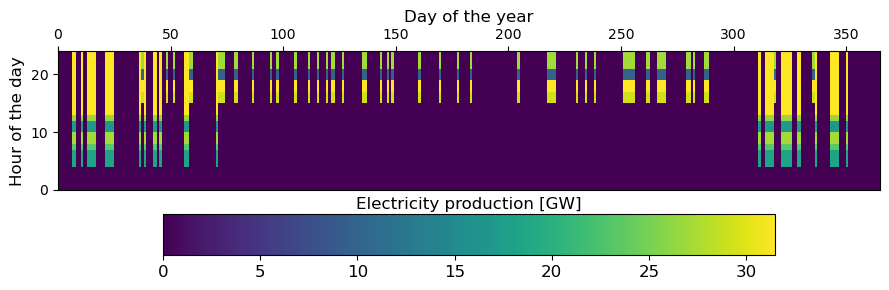

In [20]:
fn.plotOperationColorMap(
    esM,
    "Gas power plants",
    "south",
    ip=2040,
    figsize=(9, 3),
    xlabel="Day of the year",
    ylabel="Hour of the day",
    zlabel="Electricity production [GW]",
);

## Where to go from here

You have now built, optimized and analyzed a complete energy system model with FINE. To go further:

- The component notebooks build on this model and introduce further parameters of each component type:
  - [Sources](_3_sources.ipynb): offshore wind turbines, an expansion target and existing run-of-river plants
  - [Sinks](_4_sinks.ipynb): a CO<sub>2</sub> price instead of a CO<sub>2</sub> limit and electricity exports
  - [Conversions](_5_conversions.ipynb): existing gas power plants and electrolyzers that produce hydrogen
  - [Storages](_6_storages.ipynb): existing pumped hydro storage and seasonal hydrogen storage in salt caverns
  - [Transmissions](_7_transmissions.ipynb): the existing grid and HVDC cables
- The **User Guide** contains the mathematical description of every component.
- The other **Examples** show larger models and advanced features such as spatial aggregation, stochastic optimization or saving models to NetCDF files.

Some things to try with this model:

- Lower the CO<sub>2</sub> limit for 2040 to 0. What has to change in the system?
- Remove the AC cables. How do the capacities in each region change?
- Increase the number of typical days in `aggregateTemporally` and compare the results.